# Practical Lab — Building AI Agents with LangGraph

**Course:** Advanced Artificial Intelligence / Generative AI 
**Attendees** PHD Students.
**Technology:** Python, LangChain, LangGraph, LLM APIs  
**Level:** Intermediate | **Format:** Jupyter Notebook

## 1. Lab objectives

At the end of this lab, you should be able to:

- Explain the difference between a conventional LLM chain and an agentic workflow.
- Understand the main LangGraph concepts: **State, Nodes, Edges, Conditional edges, Graph execution**.
- Build a simple conversational agent and add memory/state to it.
- Implement conditional routing and integrate tools.
- Build a multi-step research-style agent that can decide which action to perform.
- Visualize and test the resulting graph, and evaluate its behavior.

> **Tip:** Write your answers to the conceptual questions in the *"Your answer"* cells. They form part of your final report.

## PART I — Environment setup
### Exercise 1 — Install LangGraph

In [2]:
import sys
from importlib.metadata import version

print("Python:", sys.version)
print("Executable:", sys.executable)
print("LangGraph:", version("langgraph"))
print("LangChain:", version("langchain"))


Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Executable: C:\Users\Cloud\langgraph-env\Scripts\python.exe
LangGraph: 1.2.18
LangChain: 1.4.7


In [1]:
!pip install -U langgraph langchain langchain-openai langchain-community

  Using cached langgraph-1.2.18-py3-none-any.whl.metadata (4.9 kB)
  Using cached langchain-1.4.7-py3-none-any.whl.metadata (6.2 kB)
  Using cached langchain_openai-1.7.3-py3-none-any.whl.metadata (3.6 kB)
  Using cached langchain_community-0.4.2-py3-none-any.whl.metadata (3.4 kB)
  Using cached langchain_core-1.7.0-py3-none-any.whl.metadata (4.8 kB)
  Using cached langgraph_checkpoint-4.3.1-py3-none-any.whl.metadata (6.7 kB)
  Using cached langgraph_prebuilt-1.1.1-py3-none-any.whl.metadata (6.9 kB)
  Using cached langgraph_sdk-0.4.10-py3-none-any.whl.metadata (5.1 kB)
  Using cached pydantic-2.14.1-py3-none-any.whl.metadata (133 kB)
  Using cached xxhash-4.0.2-cp315-cp315-win_amd64.whl.metadata (18 kB)
  Using cached jsonpatch-1.38-py3-none-any.whl.metadata (3.7 kB)
  Using cached langchain_protocol-0.0.20-py3-none-any.whl.metadata (2.4 kB)
  Using cached langsmith-0.14.13-py3-none-any.whl.metadata (38 kB)
  Using cached tenacity-9.2.1-py3-none-any.whl.metadata (1.4 kB)
  Using cached

  error: subprocess-exited-with-error
  
  Ã— Getting requirements to build wheel did not run successfully.
  â”‚ exit code: 1
  â•°â”€> [29 lines of output]
      Traceback (most recent call last):
        File "C:\Users\Cloud\AppData\Local\Programs\Python\Python315\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 389, in <module>
          main()
          ~~~~^^
        File "C:\Users\Cloud\AppData\Local\Programs\Python\Python315\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ~~~~^^^^^^^^^^^^^^^^^^^^^^^^
        File "C:\Users\Cloud\AppData\Local\Programs\Python\Python315\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 143, in get_requires_for_build_wheel
          return hook(config_settings)
        File "C:\Users\Cloud\AppData\Local\Temp\pip-build-env-aig4um5i\overlay\Lib\sit

In [3]:
from importlib.metadata import version

print("LangGraph:", version("langgraph"))
print("LangChain:", version("langchain"))

LangGraph: 1.2.18
LangChain: 1.4.7


### Question
What is the role of:
1. **LangChain?**
2. **LangGraph?**
3. **An LLM?**

**Your answer:**  
1. *LangChain provides tools to connect language models with prompts, data, and external tools.*  
2. *LangGraph organizes an AI workflow using connected steps, shared state, and conditional routing.*  
3. *An LLM understands and generates text to answer questions and follow instructions.*

## PART II — First LangGraph workflow
### Exercise 2 — Understanding State

In LangGraph, the **state** represents the information shared between nodes.

In [4]:
from typing import TypedDict

class AgentState(TypedDict):
    message: str
    response: str

In [5]:
def process_message(state: AgentState):
    message = state["message"]
    response = f"Agent received: {message}"
    return {"response": response}

In [6]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)
graph_builder.add_node("process", process_message)
graph_builder.add_edge(START, "process")
graph_builder.add_edge("process", END)

graph = graph_builder.compile()

In [7]:
result = graph.invoke({
    "message": "Hello LangGraph!",
    "response": ""
})
print(result)

{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}


**Expected result**
```python
{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}
```

### Questions
1. What is a node?
2. What is an edge?
3. What is `START`?
4. What is `END`?
5. Why is the state passed between nodes?

**Your answer:**  
1. *A node is a processing step that reads the state and returns updates.*  
2. *An edge connects nodes and defines the execution flow.*  
3. *START is the entry point of the graph.*  
4. *END marks the end of graph execution.*  
5. *The state shares information and results between nodes.*

## PART III — Building an LLM Agent
### Exercise 3 — Connect an LLM

**Do not hard-code the API key in the notebook.** Prefer an environment variable configured outside the notebook; otherwise prompt for it securely as below.

In [11]:
%pip install -U langchain-groq


   ---------------------------------------- 0/2 [groq]
   ---------------------------------------- 0/2 [groq]
   ---------------------------------------- 0/2 [groq]
   ---------------------------------------- 0/2 [groq]
   ---------------------------------------- 0/2 [groq]
   ---------------------------------------- 0/2 [groq]
   ---------------------------------------- 2/2 [langchain-groq]

Note: you may need to restart the kernel to use updated packages.


In [13]:
import os
from groq import Groq

client = Groq(api_key=os.environ["GROQ_API_KEY"])

models = client.models.list()

for model in sorted(models.data, key=lambda m: m.id):
    print(model.id)

allam-2-7b
canopylabs/orpheus-arabic-saudi
canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-22m
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-120b
openai/gpt-oss-20b
openai/gpt-oss-safeguard-20b
qwen/qwen3.8-27b
whisper-large-v3
whisper-large-v3-turbo


In [14]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    max_tokens=1024
)

print(llm.invoke("Say hello in one short sentence.").content)

Hello!


In [15]:
import os
from getpass import getpass
from langchain_groq import ChatGroq

os.environ["GROQ_API_KEY"] = getpass(
    "Enter your Groq API key: "
).strip()

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    max_tokens=1024
)

print(llm.invoke("Say hello in one short sentence.").content)

Enter your Groq API key:  ········


Hello!


### Exercise 4 — Create an LLM node

In [16]:
class AgentState(TypedDict):
    message: str
    response: str

def chatbot(state: AgentState):
    response = llm.invoke(state["message"])
    return {"response": response.content}

graph_builder = StateGraph(AgentState)
graph_builder.add_node("chatbot", chatbot)
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

graph = graph_builder.compile()

In [18]:
result = graph.invoke({
    "message": "Explain artificial intelligence in three sentences.",
    "response": ""
})
print(result["response"])

Artificial intelligence is the simulation of human intelligence processes by machines, especially computer systems. It encompasses learning, reasoning, problem solving, perception, and language understanding, enabling tasks like image recognition, natural language processing, and autonomous decision‑making. AI is transforming industries—from healthcare to finance—by automating complex processes, uncovering insights, and creating new opportunities for innovation.


## PART IV — Multi-node AI workflow
### Exercise 5 — Build a two-stage agent

```
User question → Question analyzer → Answer generator → Final answer
```

In [19]:
class AgentState(TypedDict):
    question: str
    analysis: str
    answer: str

def analyze_question(state: AgentState):
    prompt = f"""
    Analyze the following question.

    Question:
    {state['question']}

    Identify:
    1. The topic
    2. The user's intention
    3. The information needed
    """
    response = llm.invoke(prompt)
    return {"analysis": response.content}

def generate_answer(state: AgentState):
    prompt = f"""
    Answer the user's question.

    Question:
    {state['question']}

    Analysis:
    {state['analysis']}

    Give a clear and technically correct answer.
    """
    response = llm.invoke(prompt)
    return {"answer": response.content}

In [20]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("analyzer", analyze_question)
graph_builder.add_node("answer", generate_answer)

graph_builder.add_edge(START, "analyzer")
graph_builder.add_edge("analyzer", "answer")
graph_builder.add_edge("answer", END)

graph = graph_builder.compile()

In [21]:
result = graph.invoke({
    "question": "What is reinforcement learning?",
    "analysis": "",
    "answer": ""
})
print(result["answer"])

**Reinforcement Learning (RL)** is a branch of machine learning in which an *agent* learns to make decisions by interacting with an *environment*.  The agent receives a *state* description, chooses an *action*, and then the environment returns a new state and a *reward*.  Over time the agent learns a *policy*—a mapping from states to actions—that maximizes the cumulative reward it receives.

| Component | What it is | Typical notation |
|-----------|------------|------------------|
| **Agent** | The learner or decision maker | – |
| **Environment** | The external system the agent interacts with | – |
| **State (s)** | Current situation of the environment | \(s_t\) |
| **Action (a)** | Choice made by the agent | \(a_t\) |
| **Reward (r)** | Immediate scalar feedback | \(r_t\) |
| **Policy (\(\pi\))** | Strategy for selecting actions | \(\pi(a|s)\) |
| **Value function (V or Q)** | Expected future reward from a state or state‑action pair | \(V^\pi(s)\), \(Q^\pi(s,a)\) |

### How RL diffe

## PART V — Conditional routing

This is where LangGraph becomes particularly interesting. The agent decides which branch to follow:

```
                 ┌─── Mathematics
Question ────────┼─── Programming
                 └─── General AI
```

### Exercise 6 — Create a router

In [22]:
class AgentState(TypedDict):
    question: str
    category: str
    answer: str

def classify_question(state: AgentState):
    prompt = f"""
    Classify this question into exactly one category:

    - mathematics
    - programming
    - artificial_intelligence

    Question:
    {state['question']}

    Return only the category.
    """
    response = llm.invoke(prompt)
    return {"category": response.content.strip().lower()}

### Exercise 7 — Create specialized nodes

In [23]:
def mathematics_agent(state):
    response = llm.invoke(
        f"""
        Solve this mathematics question:

        {state['question']}
        """
    )
    return {"answer": response.content}

def programming_agent(state):
    response = llm.invoke(
        f"""
        Answer this programming question.
        Include Python code when appropriate.

        {state['question']}
        """
    )
    return {"answer": response.content}

def ai_agent(state):
    response = llm.invoke(
        f"""
        Answer this artificial intelligence question
        at university level.

        {state['question']}
        """
    )
    return {"answer": response.content}

## PART VI — Conditional edges

The routing function inspects the state and returns the **name of the next branch**.

In [24]:
def route_question(state):
    category = state["category"]

    if "mathematics" in category:
        return "math"
    if "programming" in category:
        return "programming"
    return "ai"   # default / fallback branch

In [25]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("classifier", classify_question)
graph_builder.add_node("math", mathematics_agent)
graph_builder.add_node("programming", programming_agent)
graph_builder.add_node("ai", ai_agent)

graph_builder.add_edge(START, "classifier")

graph_builder.add_conditional_edges(
    "classifier",
    route_question,
    {
        "math": "math",
        "programming": "programming",
        "ai": "ai"
    }
)

graph_builder.add_edge("math", END)
graph_builder.add_edge("programming", END)
graph_builder.add_edge("ai", END)

router_graph = graph_builder.compile()

In [26]:
questions = [
    "What is the derivative of x²?",
    "How do I create a REST API with Python?",
    "What is reinforcement learning?"
]

for question in questions:
    result = router_graph.invoke({
        "question": question,
        "category": "",
        "answer": ""
    })
    print("=" * 60)
    print("QUESTION:", question)
    print("CATEGORY:", result["category"])
    print("ANSWER:", result["answer"])

QUESTION: What is the derivative of x²?
CATEGORY: mathematics
ANSWER: The derivative of \(x^2\) with respect to \(x\) is

\[
\frac{d}{dx}\,x^2 = 2x.
\]
QUESTION: How do I create a REST API with Python?
CATEGORY: programming
ANSWER: 
QUESTION: What is reinforcement learning?
CATEGORY: artificial_intelligence
ANSWER: **Reinforcement Learning (RL)** is a sub‑field of machine learning in which an *agent* learns to make a sequence of decisions by interacting with an *environment*.  The goal is to discover a *policy* that maximizes some notion of cumulative reward over time.  Unlike supervised learning, the agent receives only a scalar feedback signal (the reward) and must infer which actions lead to higher returns.

---

## 1. Formal Framework

### 1.1 Markov Decision Process (MDP)

An RL problem is usually cast as an MDP, defined by the tuple  
\[
\mathcal{M} = \langle \mathcal{S}, \mathcal{A}, P, R, \gamma \rangle
\]
where

| Symbol | Meaning |
|--------|---------|
| \(\mathcal{S}\) | Fin

## PART VII — Agent with tools
### Exercise 8 — Create tools

The original lab uses `eval()`, which is **dangerous** (it can execute arbitrary Python). Below we first show the lab version for comparison, then a **safe** calculator built on `ast` that only allows arithmetic. We use the safe one from here on.

In [27]:
from langchain_core.tools import tool

# --- Version from the lab (UNSAFE: do not use with untrusted input) ---
@tool
def calculator_unsafe(expression: str) -> str:
    """Calculate a mathematical expression (unsafe eval version)."""
    try:
        return str(eval(expression))
    except Exception:
        return "Invalid expression"

print(calculator_unsafe.invoke("25 * 4 + 10"))   # Expected: 110

110


In [28]:
import ast
import operator as op

_ALLOWED_OPS = {
    ast.Add: op.add, ast.Sub: op.sub, ast.Mult: op.mul, ast.Div: op.truediv,
    ast.Pow: op.pow, ast.Mod: op.mod, ast.FloorDiv: op.floordiv,
    ast.USub: op.neg, ast.UAdd: op.pos,
}

def _safe_eval(node):
    if isinstance(node, ast.Expression):
        return _safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.left), _safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.operand))
    raise ValueError("Unsupported expression")

@tool
def calculator(expression: str) -> str:
    """Calculate a mathematical expression such as '25 * 4 + 10'. Supports + - * / ** % //."""
    try:
        return str(_safe_eval(ast.parse(expression.strip(), mode="eval")))
    except Exception:
        return "Invalid expression"

print(calculator.invoke("25 * 4 + 10"))        # Expected: 110
print(calculator.invoke("__import__('os')"))   # Expected: Invalid expression

110
Invalid expression


In [29]:
from datetime import datetime

@tool
def current_datetime(_: str = "") -> str:
    """Return the current date and time. Use for any question about today's date or the current time."""
    return datetime.now().strftime("%A, %d %B %Y, %H:%M:%S")

print(current_datetime.invoke(""))

Tuesday, 27 October 2026, 15:31:14


## PART VIII — Tool-using agent

```
                 ┌─────────────┐
Question → Agent ├→ Calculator │
                 └─────────────┘
                       ↓
                    Answer
```

The agent must **decide** whether it needs the calculator. Expected behavior for *"What is 125 * 38?"*:

`Agent → recognizes math problem → calls calculator → receives result → generates answer`

We bind the tools to the LLM, so it can emit *tool calls*. A conditional edge sends the flow to the `tools` node when a tool call is present, then loops back to the agent.

In [47]:
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

tools = [calculator, current_datetime,search_wikipedia]
llm_with_tools = llm.bind_tools(tools)

def agent(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

tool_builder = StateGraph(MessagesState)
tool_builder.add_node("agent", agent)
tool_builder.add_node("tools", ToolNode(tools))

tool_builder.add_edge(START, "agent")
tool_builder.add_conditional_edges("agent", tools_condition)  # -> "tools" or END
tool_builder.add_edge("tools", "agent")                       # loop back with the result

tool_graph = tool_builder.compile()

In [31]:
for q in ["What is 125 * 38?", "What is the capital of Morocco?"]:
    result = tool_graph.invoke({"messages": [("user", q)]})
    print("=" * 60)
    print("Q:", q)
    for m in result["messages"]:
        m.pretty_print()

Q: What is 125 * 38?
================================ Human Message =================================

What is 125 * 38?
================================== Ai Message ==================================
Tool Calls:
  calculator (fc_b8a3c4a8-c0e2-408a-a741-8f03a9aac498)
 Call ID: fc_b8a3c4a8-c0e2-408a-a741-8f03a9aac498
  Args:
    expression: 125 * 38
================================= Tool Message =================================
Name: calculator

4750
================================== Ai Message ==================================

The result of \(125 \times 38\) is **4,750**.
Q: What is the capital of Morocco?
================================ Human Message =================================

What is the capital of Morocco?
================================== Ai Message ==================================

The capital of Morocco is **Rabat**.


**Observe:** for the first question the trace contains an `AIMessage` with a tool call, a `ToolMessage` with the result, then the final answer. For the second question, no tool is called.

## PART IX — Memory
### Exercise 9 — Conversational state

The `add_messages` reducer **appends** new messages to the list instead of overwriting it.

In [32]:
from typing import Annotated
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: ChatState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

chat_builder = StateGraph(ChatState)
chat_builder.add_node("chatbot", chatbot)
chat_builder.add_edge(START, "chatbot")
chat_builder.add_edge("chatbot", END)

**Without a checkpointer**, each `invoke` starts from scratch. **With a checkpointer** (`MemorySaver`) and a `thread_id`, the conversation persists between calls.

In [33]:
# 1) No persistence: the agent forgets
no_memory_graph = chat_builder.compile()
no_memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]})
r = no_memory_graph.invoke({"messages": [("user", "What is my name?")]})
print("WITHOUT memory:", r["messages"][-1].content)

WITHOUT memory: I’m not sure what your name is—could you let me know?


In [34]:
from langgraph.checkpoint.memory import MemorySaver

# 2) With persistence: the agent remembers within the same thread
memory_graph = chat_builder.compile(checkpointer=MemorySaver())
config = {"configurable": {"thread_id": "ahmed-1"}}

r1 = memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]}, config)
print("Agent:", r1["messages"][-1].content)

r2 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, config)
print("Agent:", r2["messages"][-1].content)

# A different thread has its own, separate memory
other = {"configurable": {"thread_id": "someone-else"}}
r3 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, other)
print("Other thread:", r3["messages"][-1].content)

Agent: Nice to meet you, Ahmed! How can I help you today?
Agent: Your name is Ahmed.
Other thread: I’m not sure what your name is—could you let me know?


## Visualizing and testing graphs

`get_graph()` returns a drawable representation. If PNG rendering is unavailable (it may need network access), print the Mermaid source and paste it into <https://mermaid.live>.

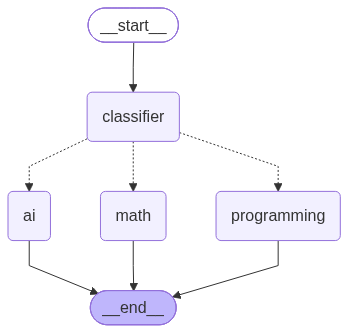

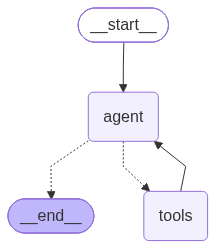

In [35]:
from IPython.display import Image, display

def show_graph(g):
    try:
        display(Image(g.get_graph().draw_mermaid_png()))
    except Exception as e:
        print("PNG rendering unavailable:", e)
        print(g.get_graph().draw_mermaid())

show_graph(router_graph)
show_graph(tool_graph)

## Evaluating the behavior of an agentic workflow

A minimal evaluation harness: define test cases with expected categories, run them, and compute accuracy. You can extend this with tool-call checks, latency, and cost.

In [37]:
import time

test_cases = [
    ("What is the derivative of x²?", "mathematics"),
    ("Solve 2x + 3 = 11", "mathematics"),
    ("How do I reverse a list in Python?", "programming"),
    ("Write a function to check for palindromes.", "programming"),
    ("What is a convolutional neural network?", "artificial_intelligence"),
    ("Explain overfitting.", "artificial_intelligence"),
]

correct, rows = 0, []
for q, expected in test_cases:
    t0 = time.time()
    out = router_graph.invoke({"question": q, "category": "", "answer": ""})
    got = out["category"]
    ok = expected in got
    correct += ok
    rows.append((q, expected, got, ok, round(time.time() - t0, 2)))

import pandas as pd
df = pd.DataFrame(rows, columns=["question", "expected", "got", "correct", "seconds"])
display(df)
print(f"Routing accuracy: {correct}/{len(test_cases)} = {correct/len(test_cases):.0%}")

,question,expected,got,correct,seconds
0,What is the derivative of x²?,mathematics,mathematics,True,3.33
1,Solve 2x + 3 = 11,mathematics,mathematics,True,0.98
2,How do I reverse a list in Python?,programming,programming,True,1.83
3,Write a function to check for palindromes.,programming,programming,True,2.88
4,What is a convolutional neural network?,artificial_intelligence,artificial_intelligence,True,3.49
5,Explain overfitting.,artificial_intelligence,artificial_intelligence,True,1.68


Routing accuracy: 6/6 = 100%


**Discussion:** Where did the router fail (if anywhere)? What would make the routing more robust (structured output, few-shot examples, enum validation)?

**Your answer:** *The router correctly classified all six test questions, achieving a routing accuracy of 100% (6/6). Both questions in each category—mathematics, programming, and artificial intelligence—were routed to the expected destination. The recorded processing times ranged from 0.98 to 3.49 seconds per question.

These results show that the router performed correctly on this small test set. However, they do not establish that it will achieve the same accuracy on unseen questions. A broader evaluation, including ambiguous questions and questions spanning multiple domains, would be needed to assess its robustness. This evaluation measures routing accuracy only; it does not assess the quality or correctness of the answers generated by the selected agents.*

## PART X — Capstone project: Intelligent University Assistant

### Requirements covered below
| # | Requirement | Implementation |
|---|---|---|
| 1 | Question classifier | `classify` node → COURSES / PROGRAMMING / MATHEMATICS / ADMINISTRATION / GENERAL |
| 2 | Specialized agents | one node per category, built with `make_agent` |
| 3 | Memory | `MemorySaver` checkpointer + `thread_id` |
| 4 | Tools | `calculator`, `current_datetime` (+ optional extras) |
| 5 | Conditional routing | `route_after_classifier`, `route_after_agent`, `route_after_tools` |
| 6 | Error handling | empty input, unknown category, invalid tool calls, API errors |

### Architecture
```
User question → Classifier ─┬→ Courses Agent ──────┐
                            ├→ Programming Agent ──┤
                            ├→ Mathematics Agent ──┼→ Tool decision ─→ Tools (Calculator / Date-time / ...)
                            ├→ Administration Agent┤        │                │
                            ├→ General Agent ──────┘        ▼                │
                            └→ Fallback (empty/error)   Final response ◄─────┘
```
Each agent decides whether to call a tool; after the tool runs, control returns to the **same** agent, which writes the final response.

In [38]:
from langchain_core.messages import SystemMessage, AIMessage, HumanMessage

CATEGORIES = ["COURSES", "PROGRAMMING", "MATHEMATICS", "ADMINISTRATION", "GENERAL"]

class AssistantState(TypedDict):
    messages: Annotated[list, add_messages]
    category: str

### 1. Classifier (with error handling)

In [39]:
def classify(state: AssistantState):
    last = state["messages"][-1]
    text = (last.content if hasattr(last, "content") else str(last)).strip()

    # Error handling: empty question
    if not text:
        return {"category": "EMPTY"}

    prompt = f"""
    Classify the student's question into exactly one category:
    COURSES (course content, syllabus, schedules, exams, grading),
    PROGRAMMING, MATHEMATICS,
    ADMINISTRATION (enrollment, fees, certificates, procedures, deadlines),
    GENERAL (anything else).

    Question: {text}

    Return only the category name.
    """
    try:
        raw = llm.invoke(prompt).content.strip().upper()
    except Exception as e:                      # Error handling: API errors
        print("Classifier API error:", e)
        return {"category": "ERROR"}

    # Error handling: unknown/unexpected label -> GENERAL
    category = next((c for c in CATEGORIES if c in raw), "GENERAL")
    return {"category": category}

### 2. Specialized agents (factory) + fallback node

In [40]:
SYSTEM_PROMPTS = {
    "COURSES": "You are a university courses advisor. Explain course content, prerequisites, "
               "schedules and study strategies. If you lack institution-specific data, say so honestly.",
    "PROGRAMMING": "You are a programming tutor. Give clear explanations and correct Python code when appropriate.",
    "MATHEMATICS": "You are a mathematics tutor. Show steps. ALWAYS use the calculator tool for arithmetic.",
    "ADMINISTRATION": "You are a university administration assistant (enrollment, fees, certificates, procedures). "
                      "Never invent official rules or deadlines; recommend contacting the administration office when unsure.",
    "GENERAL": "You are a helpful university assistant. Use the date/time tool for questions about the current date or time.",
}

def make_agent(category: str):
    system = SystemMessage(content=SYSTEM_PROMPTS[category])

    def node(state: AssistantState):
        try:
            response = llm_with_tools.invoke([system] + state["messages"])
            return {"messages": [response]}
        except Exception as e:                  # Error handling: API errors
            return {"messages": [AIMessage(
                content=f"Sorry, I ran into a technical problem while answering ({type(e).__name__}). Please try again."
            )]}
    return node

def fallback(state: AssistantState):
    if state["category"] == "EMPTY":
        msg = "Your question seems to be empty. Please type a question and I'll help."
    else:
        msg = "Sorry, I couldn't process your question right now. Please try again in a moment."
    return {"messages": [AIMessage(content=msg)]}

### 3. Routing functions and graph assembly

`ToolNode(..., handle_tool_errors=True)` converts invalid tool calls / tool exceptions into error messages the agent can recover from, instead of crashing the graph.

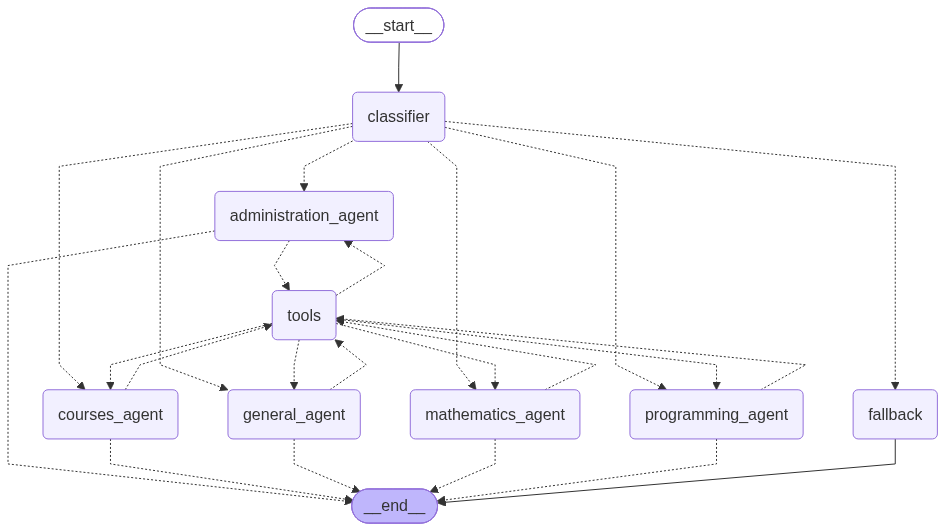

In [48]:
NODE_NAMES = {c: f"{c.lower()}_agent" for c in CATEGORIES}

def route_after_classifier(state: AssistantState):
    return NODE_NAMES.get(state["category"], "fallback")

def route_after_agent(state: AssistantState):
    last = state["messages"][-1]
    return "tools" if getattr(last, "tool_calls", None) else END

def route_after_tools(state: AssistantState):
    # return to the agent that requested the tool
    return NODE_NAMES.get(state["category"], "general_agent")

builder = StateGraph(AssistantState)
builder.add_node("classifier", classify)
builder.add_node("fallback", fallback)
builder.add_node("tools", ToolNode(tools, handle_tool_errors=True))
for c in CATEGORIES:
    builder.add_node(NODE_NAMES[c], make_agent(c))

builder.add_edge(START, "classifier")
builder.add_conditional_edges(
    "classifier", route_after_classifier,
    {**{n: n for n in NODE_NAMES.values()}, "fallback": "fallback"},
)
for c in CATEGORIES:
    builder.add_conditional_edges(NODE_NAMES[c], route_after_agent, {"tools": "tools", END: END})
builder.add_conditional_edges("tools", route_after_tools, {n: n for n in NODE_NAMES.values()})
builder.add_edge("fallback", END)

assistant = builder.compile(checkpointer=MemorySaver())
show_graph(assistant)

### 4. Demonstration — at least 5 different user queries
Includes: all categories, both tools, memory, and error cases (empty input).

In [42]:
def ask(question: str, thread_id: str = "demo"):
    config = {"configurable": {"thread_id": thread_id}}
    result = assistant.invoke({"messages": [HumanMessage(content=question)]}, config)
    print("=" * 70)
    print("USER    :", question)
    print("CATEGORY:", result["category"])
    print("ASSISTANT:", result["messages"][-1].content)
    return result

demo_queries = [
    "What topics are usually covered in a machine learning course?",     # COURSES
    "Write a Python function that computes the factorial of n.",         # PROGRAMMING
    "What is 125 * 38 + 17?",                                            # MATHEMATICS (calculator)
    "How do I request an enrollment certificate?",                       # ADMINISTRATION
    "What is today's date?",                                             # GENERAL (date/time tool)
    "   ",                                                               # Error: empty question
]
for q in demo_queries:
    ask(q)

USER    : What topics are usually covered in a machine learning course?
CATEGORY: COURSES
ASSISTANT: ### Typical Topics Covered in a Machine‑Learning Course

| Week / Module | Core Content | Key Concepts / Algorithms | Typical Assignments |
|---------------|--------------|---------------------------|---------------------|
| **1. Introduction** | • What is ML? <br>• History & applications <br>• Types of learning (supervised, unsupervised, reinforcement) | • Problem formulation <br>• Bias‑variance trade‑off <br>• Evaluation metrics (accuracy, precision, recall, ROC) | • Read a short survey paper (e.g., “A Few Useful Things to Know about Machine Learning” by Pedro Domingos). |
| **2. Foundations** | • Linear algebra refresher <br>• Probability & statistics <br>• Optimization basics | • Vectors, matrices, eigenvalues <br>• Bayes’ theorem, expectation, variance <br>• Gradient descent, convexity | • Solve a set of linear algebra problems; compute simple Bayesian updates. |
| **3. Supervised 

In [43]:
# Memory test: same thread_id
ask("My name is Ahmed.", thread_id="memory-test")
ask("What is my name?", thread_id="memory-test");

USER    : My name is Ahmed.
CATEGORY: GENERAL
ASSISTANT: Nice to meet you, Ahmed! How can I help you today?
USER    : What is my name?
CATEGORY: GENERAL
ASSISTANT: Your name is Ahmed.


In [44]:
# Inspect the full message trace (including tool calls) of one run
r = assistant.invoke(
    {"messages": [HumanMessage(content="Compute (15 + 27) * 3 using the calculator.")]},
    {"configurable": {"thread_id": "trace"}},
)
for m in r["messages"]:
    m.pretty_print()

================================ Human Message =================================

Compute (15 + 27) * 3 using the calculator.
================================== Ai Message ==================================
Tool Calls:
  calculator (fc_f8206ed1-9542-4e9e-9760-a1292e12a74b)
 Call ID: fc_f8206ed1-9542-4e9e-9760-a1292e12a74b
  Args:
    expression: (15 + 27) * 3
================================= Tool Message =================================
Name: calculator

126
================================== Ai Message ==================================

**Step 1:** Add the numbers inside the parentheses.  
\(15 + 27 = 42\)

**Step 2:** Multiply the result by 3.  
\(42 \times 3 = 126\)

**Answer:** \((15 + 27) \times 3 = 126\)


### 5. Optional extensions
Add one or more of: Wikipedia, web search, a database (e.g. SQLite with course data), a PDF reader, or weather. Implement each as a `@tool`, append it to the `tools` list **before** calling `llm.bind_tools(...)`, and rebuild the graph.

```python
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
wiki = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
```

In [49]:
wiki_result = assistant.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Use the search_wikipedia tool to find information "
                    "about Alan Turing, then give a short summary."
                )
            )
        ]
    },
    {"configurable": {"thread_id": "wiki-test-1"}},
)

print("CATEGORY:", wiki_result["category"])

for message in wiki_result["messages"]:
    message.pretty_print()

CATEGORY: GENERAL
================================ Human Message =================================

Use the search_wikipedia tool to find information about Alan Turing, then give a short summary.
================================== Ai Message ==================================
Tool Calls:
  search_wikipedia (fc_b1962648-1a18-40b0-8ad9-ac9b7b0eefb7)
 Call ID: fc_b1962648-1a18-40b0-8ad9-ac9b7b0eefb7
  Args:
    query: Alan Turing
================================= Tool Message =================================
Name: search_wikipedia

Error: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')
 Please fix your mistakes.
================================== Ai Message ==================================
Tool Calls:
  search_wikipedia (fc_c3b3f1e1-0a75-414c-976e-b8e608e58fc5)
 Call ID: fc_c3b3f1e1-0a75-414c-976e-b8e608e58fc5
  Args:
    query: Alan Turing
================================= Tool Message =================================
Name: search_wikipedia

Error: JSONDecodeError('Expec

In [53]:
import wikipedia
from langchain_core.tools import tool
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

wikipedia.set_user_agent(
    "UniversityAssistantLab/1.0 (educational notebook)"
)

wiki = WikipediaQueryRun(
    api_wrapper=WikipediaAPIWrapper(
        top_k_results=1,
        doc_content_chars_max=2000,
    )
)

@tool
def search_wikipedia(query: str) -> str:
    """Search Wikipedia for factual information about a topic."""
    return wiki.invoke({"query": query})

In [51]:
wiki_result = assistant.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Use the search_wikipedia tool to find information "
                    "about Alan Turing, then give a short summary."
                )
            )
        ]
    },
    {"configurable": {"thread_id": "wiki-test-2"}},
)

print("CATEGORY:", wiki_result["category"])

for message in wiki_result["messages"]:
    message.pretty_print()

CATEGORY: GENERAL
================================ Human Message =================================

Use the search_wikipedia tool to find information about Alan Turing, then give a short summary.
================================== Ai Message ==================================
Tool Calls:
  search_wikipedia (fc_f3c30fb9-8cea-4949-87a8-fa668645f787)
 Call ID: fc_f3c30fb9-8cea-4949-87a8-fa668645f787
  Args:
    query: Alan Turing
================================= Tool Message =================================
Name: search_wikipedia

Page: Alan Turing
Summary: Alan Mathison Turing (; 23 June 1912 – 7 June 1954) was an English mathematician and logician widely regarded as the father of theoretical computer science. He formalised the concepts of algorithm and computation with the Turing machine, a model of a general-purpose computer, and his contributions to cryptanalysis helped the Allies of World War II decipher messages encrypted by the German Enigma machine. He also contributed the Turin

## Deliverables checklist

- [ ] `langgraph_lab.ipynb` (this notebook, executed, with outputs)
- [ ] `README.md` (setup, how to run, design choices)
- [ ] Source code
- [ ] Architecture diagram (export from `show_graph(assistant)` or Mermaid)
- [ ] Screenshots showing execution
- [ ] Short report answering the conceptual questions